<a href="https://colab.research.google.com/github/2952342H/Battery-Analysis/blob/main/BATCH_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Upload the available Batch 2 Excel files:
  001.01.xlsx
  001.02.xlsx
  001.03.xlsx
  002.01.xlsx
  002.02.xlsx
  002.03.xlsx
  003.01.xlsx


Saving 001.01.xlsx to 001.01.xlsx
Saving 002.01.xlsx to 002.01.xlsx
Saving 003.01.xlsx to 003.01.xlsx
Saving 001.03.xlsx to 001.03.xlsx
Saving 002.02.xlsx to 002.02.xlsx
Saving 002.03.xlsx to 002.03.xlsx
Saving 001.02.xlsx to 001.02.xlsx

Current status:


,cell,current_cycle,current_step,current_step_time_h,last_voltage_V,last_current_mA,actual_first_charge_C
0,001.01,1,CC Chg,129.1250,1.2886,0.122,0.1000
1,001.02,1,CC Chg,11.4333,1.6609,0.122,0.0872
2,001.03,1,CC Chg,11.4417,0.0102,0.122,0.0953
3,002.01,2,CC Chg,13.5667,4.5423,0.122,0.1000
4,002.02,1,CC Chg,11.4167,1.7374,0.122,0.1245
5,002.03,1,CC Chg,11.4083,1.3025,0.122,0.1000
6,003.01,29,CC DChg,0.7417,2.2237,-0.610,0.1000



Completion means that charge reached 4.8 V and discharge reached 2.0 V. It does not establish cell health.


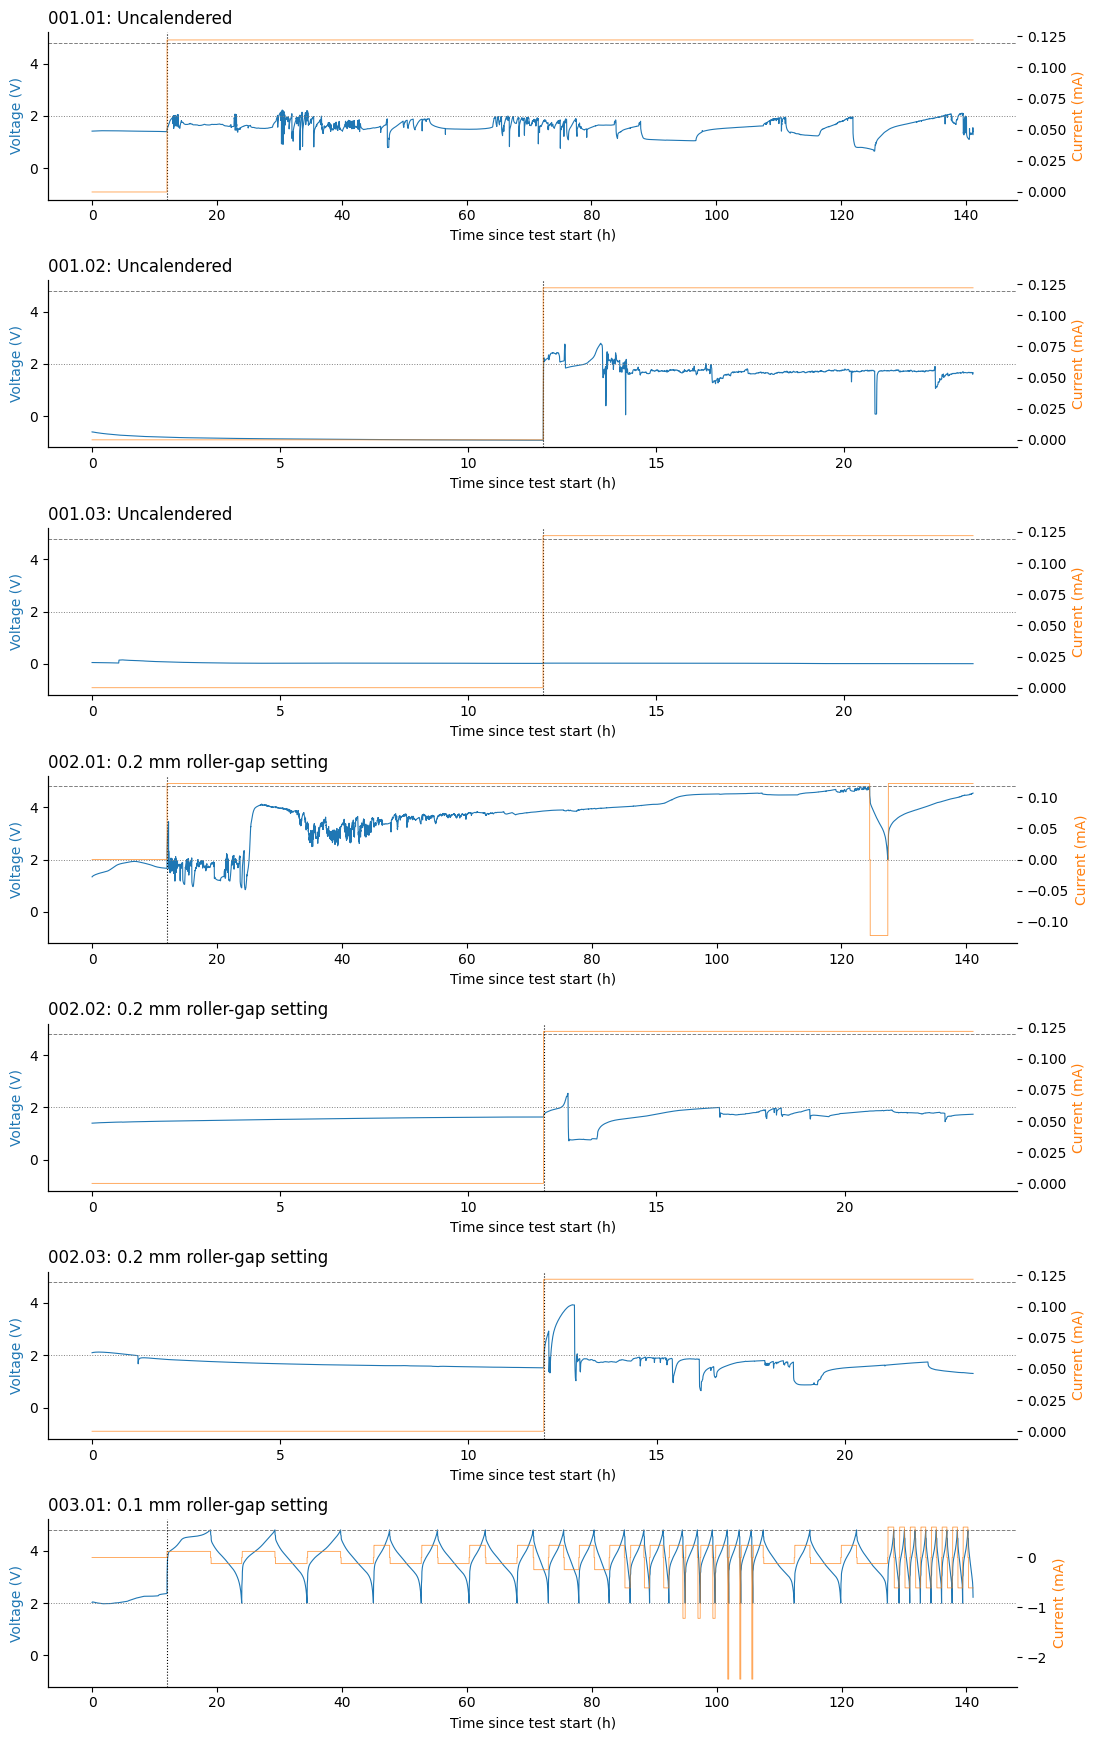

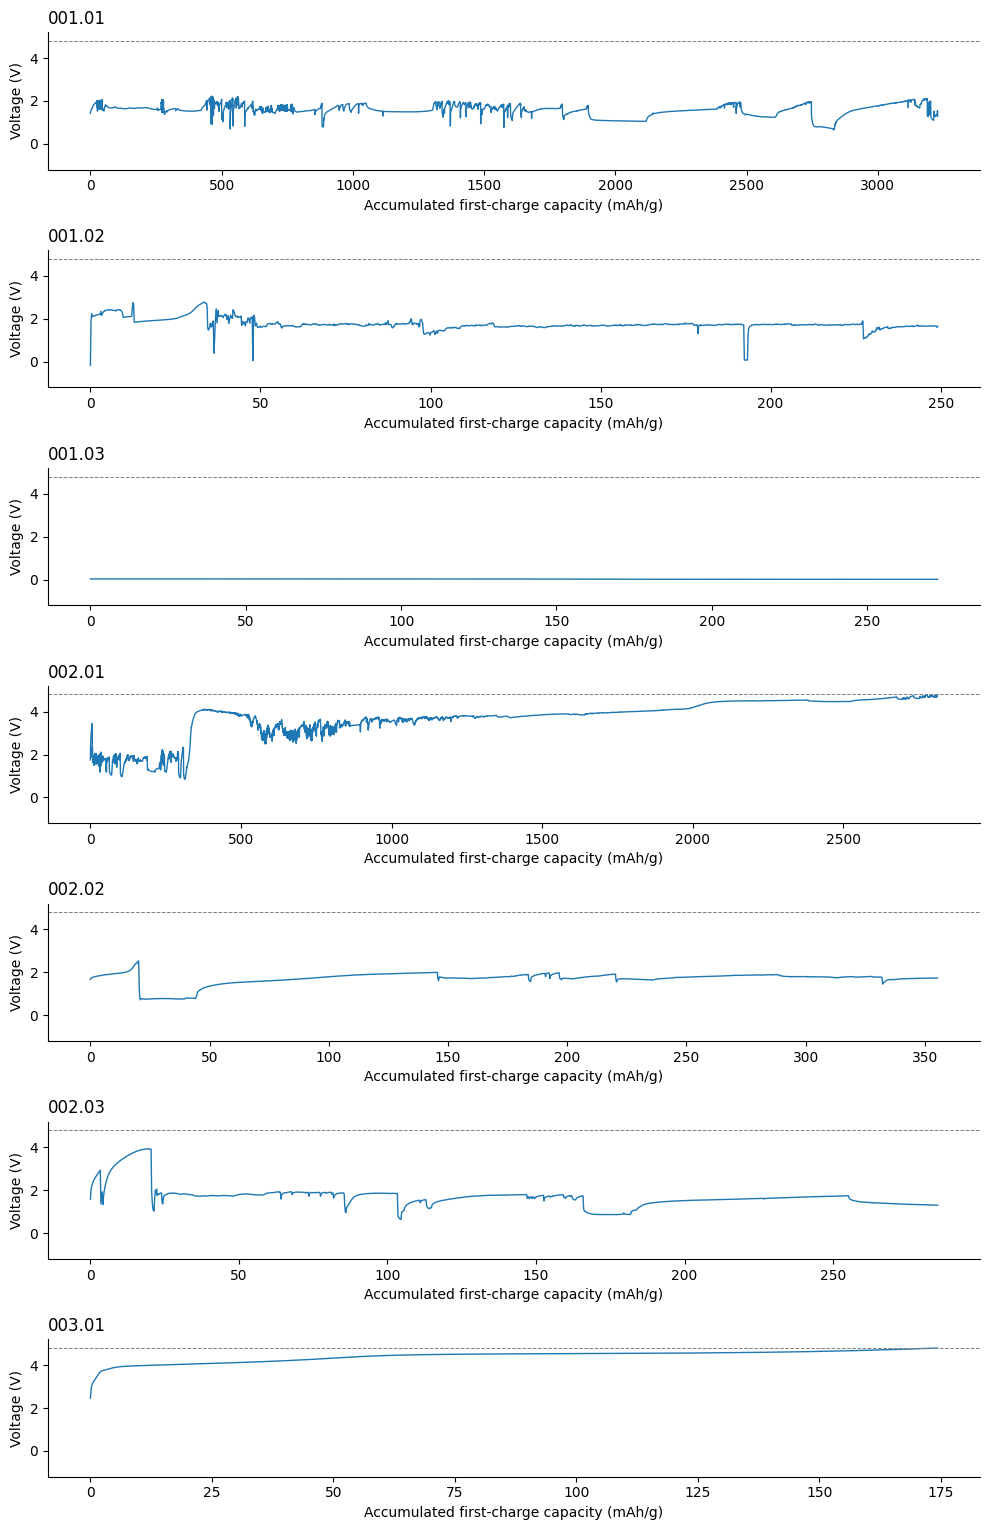

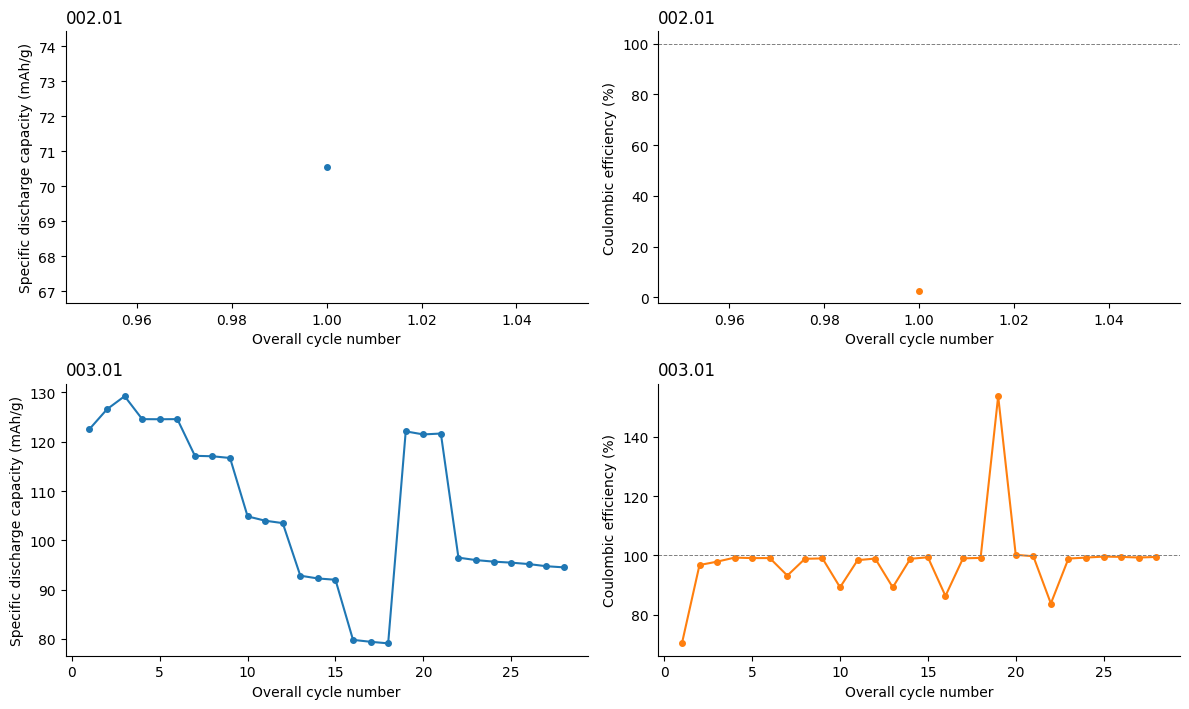

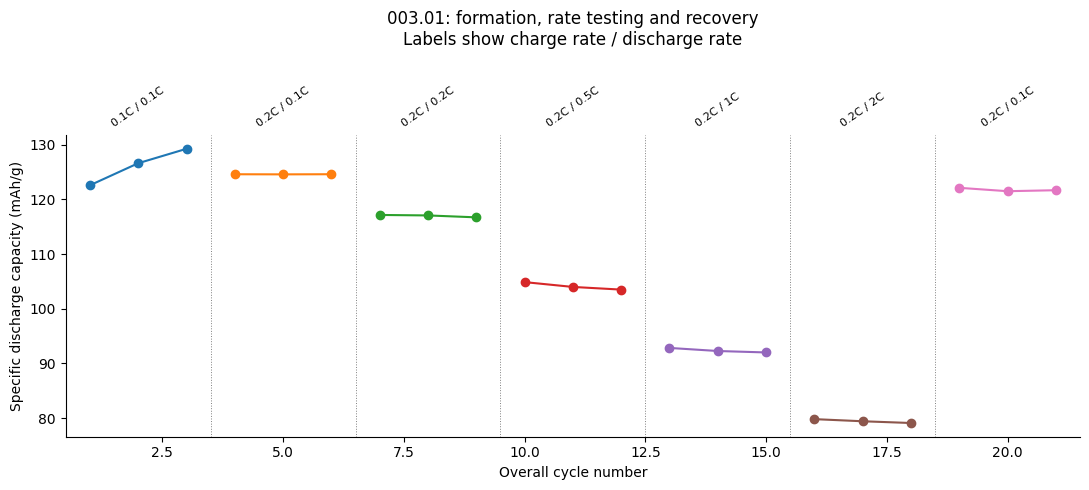

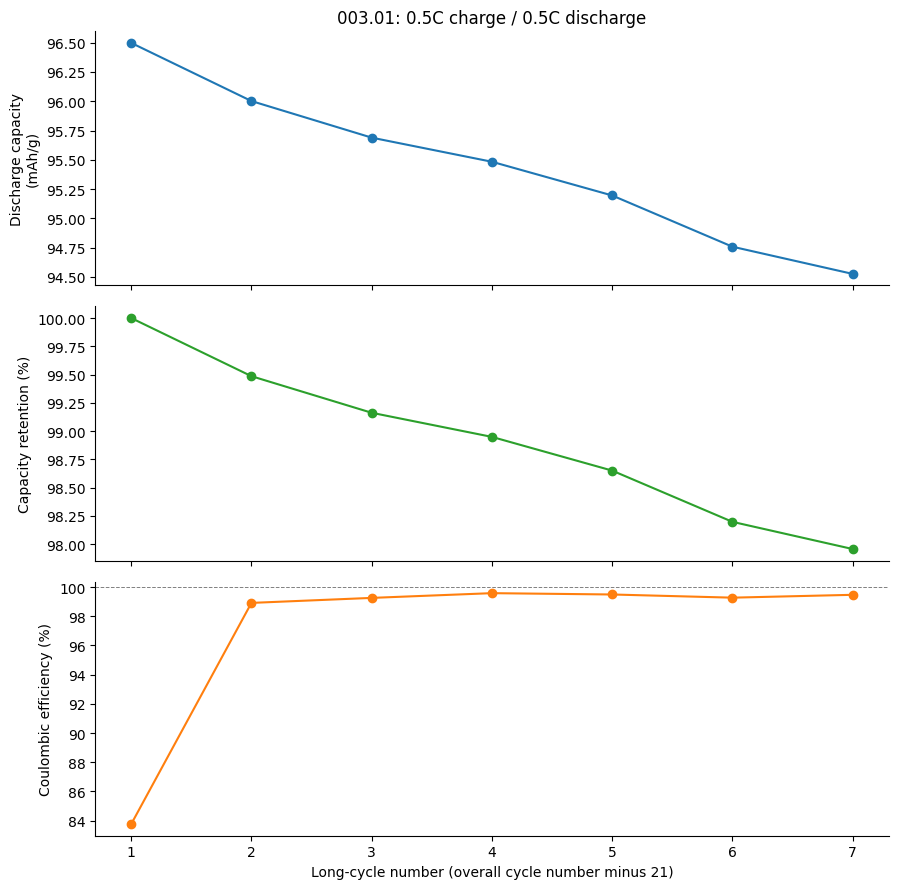


003.01 recovery, cycle 21 / cycle 6: 97.65%

Interpretation notes:
- Incomplete discharge cycles are excluded from cycle plots.
- Accumulated abnormal charge is not reversible capacity.
- Stage-transition efficiencies require separate interpretation.
- Coating thicknesses exclude the foil; constituent densities still require verification before estimating porosity.
- Samples are not averaged or automatically excluded.
- Current values are read from the records, not inferred from the programmed stage labels.

Analysis complete. Downloading the results ZIP.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import sys
import subprocess
import importlib.util

if importlib.util.find_spec("openpyxl") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "openpyxl"
    ])

import csv
import math
import shutil
import tempfile
import warnings
from pathlib import Path
from io import BytesIO
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl
from google.colab import files

warnings.filterwarnings(
    "ignore", message="Workbook contains no default style"
)



# Masses are active material masses, excluding foil, SP and PVDF.
# Thicknesses exclude the aluminium foil.



CELL_INFO = {
    "001.01": {
        "condition": "Uncalendered",
        "active_mass_mg": 4.88,
        "coating_thickness_um": 41.0,
    },
    "001.02": {
        "condition": "Uncalendered",
        "active_mass_mg": 5.60,
        "coating_thickness_um": 41.0,
    },
    "001.03": {
        "condition": "Uncalendered",
        "active_mass_mg": 5.12,
        "coating_thickness_um": 41.0,
    },
    "002.01": {
        "condition": "0.2 mm roller-gap setting",
        "active_mass_mg": 4.88,
        "coating_thickness_um": 34.0,
    },
    "002.02": {
        "condition": "0.2 mm roller-gap setting",
        "active_mass_mg": 3.92,
        "coating_thickness_um": 34.0,
    },
    "002.03": {
        "condition": "0.2 mm roller-gap setting",
        "active_mass_mg": 4.88,
        "coating_thickness_um": 34.0,
    },
    "003.01": {
        "condition": "0.1 mm roller-gap setting",
        "active_mass_mg": 4.88,
        "coating_thickness_um": 30.0,
    },
}

SPECIFIC_CAPACITY_REFERENCE = 250.0  # mAh/g
UPPER_CUTOFF = 4.8
LOWER_CUTOFF = 2.0
VOLTAGE_TOLERANCE = 0.01

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.dpi": 300,
})


def is_number(value):
    return (
        isinstance(value, (int, float))
        and not isinstance(value, bool)
        and math.isfinite(float(value))
    )


def hours(value):
    """Convert exported HH:MM:SS values to hours."""
    if value is None:
        return np.nan

    if hasattr(value, "total_seconds"):
        return value.total_seconds() / 3600

    if hasattr(value, "hour"):
        return (
            value.hour
            + value.minute / 60
            + value.second / 3600
        )

    if isinstance(value, str):
        parts = value.strip().split(":")
        if len(parts) == 3:
            try:
                h, m, s = map(float, parts)
                return h + m / 60 + s / 3600
            except ValueError:
                return np.nan

    return np.nan


def stage_name(cycle):
    if cycle <= 3:
        return "Formation: 0.1C charge / 0.1C discharge"
    if cycle <= 6:
        return "Baseline: 0.2C charge / 0.1C discharge"
    if cycle <= 9:
        return "Rate test: 0.2C discharge"
    if cycle <= 12:
        return "Rate test: 0.5C discharge"
    if cycle <= 15:
        return "Rate test: 1C discharge"
    if cycle <= 18:
        return "Rate test: 2C discharge"
    if cycle <= 21:
        return "Recovery: 0.2C charge / 0.1C discharge"
    return "Cycling: 0.5C charge / 0.5C discharge"


def read_export(content, filename):
    """Read the mixed cycle/step/record worksheet."""
    workbook = openpyxl.load_workbook(
        BytesIO(content),
        read_only=True,
        data_only=True,
    )

    try:
        if len(workbook.sheetnames) != 1:
            raise ValueError(
                f"{filename}: expected a single mixed-data worksheet."
            )

        sheet = workbook.active
        sheet.reset_dimensions()

        cycles = []
        steps = []
        records = []

        current_cycle = None
        current_step = None

        for raw_row in sheet.iter_rows(values_only=True):
            row = list(raw_row)
            row += [None] * max(0, 12 - len(row))

            if is_number(row[0]):
                current_cycle = int(row[0])
                cycles.append({
                    "cycle": current_cycle,
                    "export_charge_mAh": row[1],
                    "export_discharge_mAh": row[2],
                    "export_charge_specific_mAh_g": row[3],
                    "export_discharge_specific_mAh_g": row[4],
                    "export_CE_percent": row[5],
                })

            elif (
                is_number(row[1])
                and isinstance(row[3], str)
                and row[3] in {"Rest", "CC Chg", "CC DChg"}
            ):
                current_step = {
                    "cycle": current_cycle,
                    "step_index": int(row[1]),
                    "step_number": row[2],
                    "step_type": row[3],
                    "step_time_h": hours(row[4]),
                    "capacity_mAh": row[5],
                    "energy_Wh": row[6],
                    "start_voltage_V": row[7],
                    "end_voltage_V": row[8],
                    "segment_id": len(steps) + 1,
                }
                steps.append(current_step)

            elif (
                row[0] is None
                and row[1] is None
                and is_number(row[2])
                and current_step is not None
                and is_number(row[5])
                and is_number(row[6])
            ):
                records.append({
                    "cycle": current_cycle,
                    "segment_id": current_step["segment_id"],
                    "step_index": current_step["step_index"],
                    "step_type": current_step["step_type"],
                    "data_point": int(row[2]),
                    "step_time_h": hours(row[3]),
                    "total_time_h": hours(row[4]),
                    "current_mA": float(row[5]),
                    "voltage_V": float(row[6]),
                    "capacity_mAh": (
                        float(row[7]) if is_number(row[7]) else np.nan
                    ),
                    "energy_Wh": (
                        float(row[8]) if is_number(row[8]) else np.nan
                    ),
                    "date": row[9],
                })

        if not records:
            raise ValueError(
                f"{filename}: no measurement records were found."
            )

        return (
            pd.DataFrame(cycles),
            pd.DataFrame(steps),
            pd.DataFrame(records),
        )
    finally:
        workbook.close()


def evaluate_cycles(cell_id, steps, records):
    """Keep a cycle only after both voltage cutoffs are reached."""
    mass_g = CELL_INFO[cell_id]["active_mass_mg"] / 1000
    completed = []
    checks = []

    for cycle, cycle_steps in steps.groupby("cycle", sort=True):
        charge_steps = cycle_steps[
            cycle_steps["step_type"] == "CC Chg"
        ]
        discharge_steps = cycle_steps[
            cycle_steps["step_type"] == "CC DChg"
        ]

        charge_ok = False
        discharge_ok = False
        charge_records = pd.DataFrame()
        discharge_records = pd.DataFrame()

        if len(charge_steps):
            charge_step = charge_steps.iloc[-1]
            charge_records = records[
                records["segment_id"] == charge_step["segment_id"]
            ]

            if len(charge_records):
                charge_ok = (
                    abs(
                        charge_step["end_voltage_V"] - UPPER_CUTOFF
                    ) <= VOLTAGE_TOLERANCE
                    and abs(
                        charge_records.iloc[-1]["voltage_V"]
                        - UPPER_CUTOFF
                    ) <= VOLTAGE_TOLERANCE
                )

        if len(discharge_steps):
            discharge_step = discharge_steps.iloc[-1]
            discharge_records = records[
                records["segment_id"] == discharge_step["segment_id"]
            ]

            if len(discharge_records):
                discharge_ok = (
                    abs(
                        discharge_step["end_voltage_V"] - LOWER_CUTOFF
                    ) <= VOLTAGE_TOLERANCE
                    and abs(
                        discharge_records.iloc[-1]["voltage_V"]
                        - LOWER_CUTOFF
                    ) <= VOLTAGE_TOLERANCE
                )

        checks.append({
            "cell": cell_id,
            "cycle": int(cycle),
            "charge_cutoff_reached": charge_ok,
            "discharge_cutoff_reached": discharge_ok,
            "complete_charge_discharge": charge_ok and discharge_ok,
        })

        if not (charge_ok and discharge_ok):
            continue

        charge_q = float(charge_step["capacity_mAh"])
        discharge_q = float(discharge_step["capacity_mAh"])

        if charge_q <= 0 or discharge_q <= 0:
            continue

        discharge_energy = float(discharge_step["energy_Wh"])
        charge_current = abs(
            charge_records["current_mA"].median()
        )
        discharge_current = abs(
            discharge_records["current_mA"].median()
        )
        one_c_mA = mass_g * SPECIFIC_CAPACITY_REFERENCE

        completed.append({
            "cell": cell_id,
            "cycle": int(cycle),
            "stage": stage_name(int(cycle)),
            "active_mass_mg": mass_g * 1000,
            "charge_mAh": charge_q,
            "discharge_mAh": discharge_q,
            "charge_specific_mAh_g": charge_q / mass_g,
            "discharge_specific_mAh_g": discharge_q / mass_g,
            "CE_percent": 100 * discharge_q / charge_q,
            "discharge_energy_Wh": discharge_energy,
            "discharge_specific_energy_Wh_kg": (
                discharge_energy / (mass_g / 1000)
            ),
            "mean_discharge_voltage_V": (
                discharge_energy * 1000 / discharge_q
            ),
            "charge_current_mA": charge_current,
            "discharge_current_mA": discharge_current,
            "actual_charge_C": charge_current / one_c_mA,
            "actual_discharge_C": discharge_current / one_c_mA,
        })

    return pd.DataFrame(completed), pd.DataFrame(checks)


def current_status(cell_id, steps, records):
    info = CELL_INFO[cell_id]
    last = records.iloc[-1]
    last_segment = records[
        records["segment_id"] == last["segment_id"]
    ]

    charge = records[records["step_type"] == "CC Chg"]
    first_charge = pd.DataFrame()

    if len(charge):
        first_segment_id = charge.iloc[0]["segment_id"]
        first_charge = charge[
            charge["segment_id"] == first_segment_id
        ]

    one_c_mA = (
        info["active_mass_mg"] / 1000
        * SPECIFIC_CAPACITY_REFERENCE
    )

    first_charge_current = (
        abs(first_charge["current_mA"].median())
        if len(first_charge) else np.nan
    )

    return {
        "cell": cell_id,
        "condition": info["condition"],
        "active_mass_mg": info["active_mass_mg"],
        "coating_thickness_um": info["coating_thickness_um"],
        "first_record_date": records.iloc[0]["date"],
        "last_record_date": last["date"],
        "total_time_h": last["total_time_h"],
        "current_cycle": int(last["cycle"]),
        "current_step": last["step_type"],
        "current_step_time_h": last["step_time_h"],
        "last_voltage_V": last["voltage_V"],
        "last_current_mA": last["current_mA"],
        "current_step_capacity_mAh": last["capacity_mAh"],
        "initial_voltage_V": records.iloc[0]["voltage_V"],
        "minimum_voltage_V": records["voltage_V"].min(),
        "maximum_voltage_V": records["voltage_V"].max(),
        "first_charge_current_mA": first_charge_current,
        "expected_0.1C_current_mA": one_c_mA * 0.1,
        "actual_first_charge_C": first_charge_current / one_c_mA,
        "first_charge_time_h": (
            first_charge.iloc[-1]["step_time_h"]
            if len(first_charge) else np.nan
        ),
        "first_charge_capacity_mAh": (
            first_charge.iloc[-1]["capacity_mAh"]
            if len(first_charge) else np.nan
        ),
        "current_segment_min_voltage_V": (
            last_segment["voltage_V"].min()
        ),
        "current_segment_max_voltage_V": (
            last_segment["voltage_V"].max()
        ),
    }


def save_figure(fig, output_dir, name):
    fig.savefig(
        output_dir / f"{name}.png",
        dpi=300,
        bbox_inches="tight",
    )
    fig.savefig(
        output_dir / f"{name}.pdf",
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)


def plot_time_records(all_records, output_dir):
    count = len(all_records)
    fig, axes = plt.subplots(
        count, 1,
        figsize=(11, 2.5 * count),
        squeeze=False,
    )

    for ax, (cell_id, records) in zip(
        axes[:, 0], all_records.items()
    ):
        ax.plot(
            records["total_time_h"],
            records["voltage_V"],
            color="tab:blue",
            linewidth=0.8,
        )
        ax.axhline(
            UPPER_CUTOFF, color="grey",
            linestyle="--", linewidth=0.7,
        )
        ax.axhline(
            LOWER_CUTOFF, color="grey",
            linestyle=":", linewidth=0.7,
        )
        ax.axvline(
            12, color="black",
            linestyle=":", linewidth=0.8,
        )
        ax.set_ylim(-1.2, 5.2)
        ax.set_ylabel("Voltage (V)", color="tab:blue")
        ax.set_xlabel("Time since test start (h)")
        ax.set_title(
            f"{cell_id}: {CELL_INFO[cell_id]['condition']}",
            loc="left",
        )

        current_ax = ax.twinx()
        current_ax.plot(
            records["total_time_h"],
            records["current_mA"],
            color="tab:orange",
            linewidth=0.65,
            alpha=0.7,
        )
        current_ax.set_ylabel(
            "Current (mA)", color="tab:orange"
        )
        current_ax.spines["top"].set_visible(False)

    fig.tight_layout()
    save_figure(fig, output_dir, "All_Cells_Voltage_Current_Time")


def plot_first_charge(all_records, output_dir):
    fig, axes = plt.subplots(
        len(all_records), 1,
        figsize=(10, 2.2 * len(all_records)),
        squeeze=False,
    )

    for ax, (cell_id, records) in zip(
        axes[:, 0], all_records.items()
    ):
        charge = records[
            records["step_type"] == "CC Chg"
        ]

        if len(charge):
            first_id = charge.iloc[0]["segment_id"]
            charge = charge[
                charge["segment_id"] == first_id
            ]
            mass_g = CELL_INFO[cell_id]["active_mass_mg"] / 1000

            ax.plot(
                charge["capacity_mAh"] / mass_g,
                charge["voltage_V"],
                linewidth=1,
            )

        ax.axhline(
            UPPER_CUTOFF, color="grey",
            linestyle="--", linewidth=0.7,
        )
        ax.set_ylim(-1.2, 5.2)
        ax.set_title(cell_id, loc="left")
        ax.set_ylabel("Voltage (V)")
        ax.set_xlabel("Accumulated first-charge capacity (mAh/g)")

    fig.tight_layout()
    save_figure(fig, output_dir, "All_Cells_First_Charge")


def plot_completed_cycles(all_completed, output_dir):
    usable = {
        cell_id: frame
        for cell_id, frame in all_completed.items()
        if not frame.empty
    }

    if not usable:
        return

    fig, axes = plt.subplots(
        len(usable), 2,
        figsize=(12, 3.6 * len(usable)),
        squeeze=False,
    )

    for row, (cell_id, frame) in enumerate(usable.items()):
        axes[row, 0].plot(
            frame["cycle"],
            frame["discharge_specific_mAh_g"],
            "o-", markersize=4,
        )
        axes[row, 0].set_ylabel(
            "Specific discharge capacity (mAh/g)"
        )

        axes[row, 1].plot(
            frame["cycle"],
            frame["CE_percent"],
            "o-", markersize=4,
            color="tab:orange",
        )
        axes[row, 1].axhline(
            100, color="grey",
            linestyle="--", linewidth=0.7,
        )
        axes[row, 1].set_ylabel("Coulombic efficiency (%)")

        for ax in axes[row]:
            ax.set_xlabel("Overall cycle number")
            ax.set_title(cell_id, loc="left")

    fig.tight_layout()
    save_figure(fig, output_dir, "Completed_Cycles_Capacity_CE")


def plot_cell003(frame, output_dir):
    if frame.empty:
        return

    stage_groups = [
        (1, 3, "0.1C / 0.1C"),
        (4, 6, "0.2C / 0.1C"),
        (7, 9, "0.2C / 0.2C"),
        (10, 12, "0.2C / 0.5C"),
        (13, 15, "0.2C / 1C"),
        (16, 18, "0.2C / 2C"),
        (19, 21, "0.2C / 0.1C"),
    ]

    fig, ax = plt.subplots(figsize=(11, 5))
    colors = plt.cm.tab10.colors

    for index, (start, end, label) in enumerate(stage_groups):
        selected = frame[
            frame["cycle"].between(start, end)
        ]

        if selected.empty:
            continue

        ax.plot(
            selected["cycle"],
            selected["discharge_specific_mAh_g"],
            "o-", color=colors[index],
        )
        ax.text(
            (start + end) / 2, 1.02,
            label,
            transform=ax.get_xaxis_transform(),
            ha="center", va="bottom",
            fontsize=8, rotation=35,
        )

    for boundary in [3.5, 6.5, 9.5, 12.5, 15.5, 18.5]:
        ax.axvline(
            boundary, color="grey",
            linestyle=":", linewidth=0.7,
        )

    ax.set_xlim(0.5, 21.5)
    ax.set_xlabel("Overall cycle number")
    ax.set_ylabel("Specific discharge capacity (mAh/g)")
    ax.set_title(
        "003.01: formation, rate testing and recovery\n"
        "Labels show charge rate / discharge rate",
        pad=65,
    )
    fig.tight_layout()
    save_figure(fig, output_dir, "003_01_Rate_Test_and_Recovery")

    long_cycles = frame[frame["cycle"] >= 22].copy()

    if long_cycles.empty:
        return

    long_cycles["long_cycle"] = long_cycles["cycle"] - 21
    first_capacity = long_cycles.iloc[0][
        "discharge_specific_mAh_g"
    ]
    long_cycles["retention_percent"] = (
        long_cycles["discharge_specific_mAh_g"]
        / first_capacity * 100
    )
    long_cycles.to_csv(
        output_dir / "003_01_Long_Cycling.csv",
        index=False,
    )

    fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)

    axes[0].plot(
        long_cycles["long_cycle"],
        long_cycles["discharge_specific_mAh_g"],
        "o-",
    )
    axes[0].set_ylabel("Discharge capacity\n(mAh/g)")
    axes[0].set_title("003.01: 0.5C charge / 0.5C discharge")

    axes[1].plot(
        long_cycles["long_cycle"],
        long_cycles["retention_percent"],
        "o-", color="tab:green",
    )
    axes[1].set_ylabel("Capacity retention (%)")

    axes[2].plot(
        long_cycles["long_cycle"],
        long_cycles["CE_percent"],
        "o-", color="tab:orange",
    )
    axes[2].axhline(
        100, color="grey",
        linestyle="--", linewidth=0.7,
    )
    axes[2].set_ylabel("Coulombic efficiency (%)")
    axes[2].set_xlabel(
        "Long-cycle number (overall cycle number minus 21)"
    )

    fig.tight_layout()
    save_figure(fig, output_dir, "003_01_Long_Cycling")


def main():
    print("Upload the available Batch 2 Excel files:")
    for cell_id in CELL_INFO:
        print(f"  {cell_id}.xlsx")

    uploaded = files.upload()

    if not uploaded:
        raise ValueError("No files were uploaded.")

    output_dir = Path(tempfile.mkdtemp(prefix="batch2_review_"))
    all_records = {}
    all_completed = {}
    all_checks = []
    statuses = []

    for cell_id in CELL_INFO:
        filename = f"{cell_id}.xlsx"

        if filename not in uploaded:
            print(f"Not uploaded: {filename}")
            continue

        cycles, steps, records = read_export(
            uploaded[filename], filename
        )

        completed, checks = evaluate_cycles(
            cell_id, steps, records
        )

        all_records[cell_id] = records
        all_completed[cell_id] = completed
        all_checks.append(checks)
        statuses.append(current_status(cell_id, steps, records))

        records.to_csv(
            output_dir / f"{cell_id}_Records.csv",
            index=False,
        )
        steps.to_csv(
            output_dir / f"{cell_id}_Steps.csv",
            index=False,
        )
        cycles.to_csv(
            output_dir / f"{cell_id}_Export_Cycle_Summary.csv",
            index=False,
        )

    if not all_records:
        raise ValueError(
            "No recognised filenames were uploaded. "
            "Use names such as 001.01.xlsx."
        )

    status_df = pd.DataFrame(statuses)
    status_df.to_csv(
        output_dir / "Cell_Status.csv", index=False
    )

    completed_frames = [
        frame for frame in all_completed.values()
        if not frame.empty
    ]

    if completed_frames:
        completed_df = pd.concat(
            completed_frames, ignore_index=True
        )
        completed_df.to_csv(
            output_dir / "Completed_Cycles.csv",
            index=False,
        )

    if all_checks:
        pd.concat(all_checks, ignore_index=True).to_csv(
            output_dir / "Cycle_Cutoff_Checks.csv",
            index=False,
        )

    print("\nCurrent status:")
    display_columns = [
        "cell",
        "current_cycle",
        "current_step",
        "current_step_time_h",
        "last_voltage_V",
        "last_current_mA",
        "actual_first_charge_C",
    ]
    display(status_df[display_columns].round(4))

    print(
        "\nCompletion means that charge reached 4.8 V and "
        "discharge reached 2.0 V. It does not establish cell health."
    )

    plot_time_records(all_records, output_dir)
    plot_first_charge(all_records, output_dir)
    plot_completed_cycles(all_completed, output_dir)

    if "003.01" in all_completed:
        plot_cell003(all_completed["003.01"], output_dir)

        frame = all_completed["003.01"]

        baseline = frame[frame["cycle"] == 6]
        recovery = frame[frame["cycle"] == 21]

        if len(baseline) and len(recovery):
            recovery_percent = (
                recovery.iloc[0]["discharge_specific_mAh_g"]
                / baseline.iloc[0]["discharge_specific_mAh_g"]
                * 100
            )
            print(
                "\n003.01 recovery, cycle 21 / cycle 6: "
                f"{recovery_percent:.2f}%"
            )

    print(
        "\nInterpretation notes:\n"
        "- Incomplete discharge cycles are excluded from cycle plots.\n"
        "- Accumulated abnormal charge is not reversible capacity.\n"
        "- Stage-transition efficiencies require separate interpretation.\n"
        "- Coating thicknesses exclude the foil; constituent densities "
        "still require verification before estimating porosity.\n"
        "- Samples are not averaged or automatically excluded.\n"
        "- Current values are read from the records, not inferred "
        "from the programmed stage labels."
    )

    archive = shutil.make_archive(
        str(output_dir.parent / f"{output_dir.name}_results"),
        "zip",
        root_dir=output_dir,
    )

    print("\nAnalysis complete. Downloading the results ZIP.")
    files.download(archive)


main()